In [1]:
# =====================================================
# APPLICATION 1: BALANCED PARENTHESES CHECKER
# PDA AND CFG IMPLEMENTATION
# =====================================================

# STEP 1: Define PDA components
alphabet = ['(', ')']
initial_state = 'q0'
final_state = 'qf'
bottom_symbol = '$'

# CFG production
grammar = {
    'S': ['(S)S', 'ε']
}

# STEP 2: Implement PDA using stack
def balanced_pda(text, trace=True):

    stack = [bottom_symbol]
    current_state = initial_state

    if trace:
        print("\nInput:", repr(text))
        print("Initial Stack:", stack)

    for symbol in text:

        if symbol == '(':
            stack.append('(')

        elif symbol == ')':
            if stack[-1] == '(':
                stack.pop()
            else:
                current_state = 'qd'
                if trace:
                    print("Invalid closing parenthesis")
                break

        else:
            current_state = 'qd'
            if trace:
                print("Invalid input symbol:", symbol)
            break

        if trace:
            print("Read:", symbol, "| Stack:", stack)

    # STEP 3: Check acceptance
    if current_state != 'qd' and stack == [bottom_symbol]:
        current_state = final_state
    else:
        current_state = 'qd'

    result = "ACCEPTED" if current_state == final_state else "REJECTED"

    if trace:
        print("Final State:", current_state)
        print("Result:", result)

    return result


# STEP 4: Test cases
test_cases = [
    "()",
    "(())",
    "()()",
    "(()())",
    "(()",
    "())",
    ")(",
    "((()))"
]

print("BALANCED PARENTHESES TEST RESULTS")
print("=" * 40)

for test in test_cases:
    print(test, ":", balanced_pda(test, False))


# STEP 5: Accept user input
user_input = input("\nEnter parentheses: ")
balanced_pda(user_input)

BALANCED PARENTHESES TEST RESULTS
() : ACCEPTED
(()) : ACCEPTED
()() : ACCEPTED
(()()) : ACCEPTED
(() : REJECTED
()) : REJECTED
)( : REJECTED
((())) : ACCEPTED

Enter parentheses: )()))()))

Input: ')()))()))'
Initial Stack: ['$']
Invalid closing parenthesis
Final State: qd
Result: REJECTED


'REJECTED'

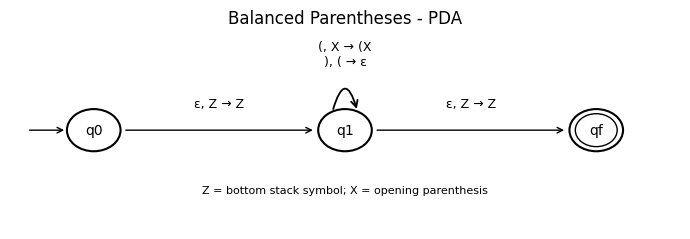

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(7, 2.5))

ax.set_xlim(0, 8)
ax.set_ylim(0, 3)
ax.axis('off')

# STEP 1: Draw states
states = {
    'q0': (1, 1.5),
    'q1': (4, 1.5),
    'qf': (7, 1.5)
}

for name, (x, y) in states.items():
    ax.add_patch(Circle((x, y), 0.32,
                        fill=False, linewidth=1.5))
    if name == 'qf':
        ax.add_patch(Circle((x, y), 0.25,
                            fill=False, linewidth=1))
    ax.text(x, y, name, ha='center',
            va='center', fontsize=10)

# STEP 2: Initial arrow
ax.annotate('', xy=(0.68, 1.5), xytext=(0.2, 1.5),
            arrowprops=dict(arrowstyle='->'))

# STEP 3: Transition q0 to q1
ax.annotate('', xy=(3.65, 1.5), xytext=(1.35, 1.5),
            arrowprops=dict(arrowstyle='->'))

ax.text(2.5, 1.85, 'ε, Z → Z',
        ha='center', fontsize=9)

# STEP 4: Self-loop for stack operations
loop = FancyArrowPatch(
    (3.85, 1.78), (4.15, 1.78),
    connectionstyle="arc3,rad=-1.8",
    arrowstyle='->',
    mutation_scale=12,
    linewidth=1.3
)
ax.add_patch(loop)

ax.text(4, 2.65,
        '(, X → (X\n), ( → ε',
        ha='center', va='center', fontsize=9)

# STEP 5: Transition to final state
ax.annotate('', xy=(6.65, 1.5), xytext=(4.35, 1.5),
            arrowprops=dict(arrowstyle='->'))

ax.text(5.5, 1.85, 'ε, Z → Z',
        ha='center', fontsize=9)

ax.text(4, 0.55,
        'Z = bottom stack symbol; X = opening parenthesis',
        ha='center', fontsize=8)

plt.title('Balanced Parentheses - PDA', fontsize=12)
plt.tight_layout()
plt.show()

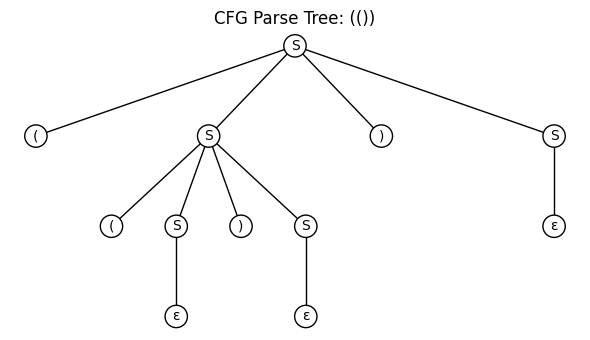

In [6]:
# BALANCED PARENTHESES - CFG PARSE TREE

import matplotlib.pyplot as plt

def parentheses_tree(text):

    if balanced_pda(text, False) != "ACCEPTED":
        print("Invalid string. No parse tree.")
        return

    nodes = []
    edges = []

    def build(s, parent=None):

        index = len(nodes)
        nodes.append("S")

        if parent is not None:
            edges.append((parent, index))

        if s == "":
            eps = len(nodes)
            nodes.append("ε")
            edges.append((index, eps))
            return index

        depth = 0

        for i, ch in enumerate(s):
            depth += 1 if ch == '(' else -1
            if depth == 0:
                match = i
                break

        left = len(nodes)
        nodes.append("(")
        edges.append((index, left))

        build(s[1:match], index)

        right = len(nodes)
        nodes.append(")")
        edges.append((index, right))

        build(s[match+1:], index)

        return index

    build(text)

    # STEP 1: Calculate tree levels
    levels = {}

    def assign_levels(node, level):
        levels[node] = level
        children = [b for a, b in edges if a == node]

        for child in children:
            assign_levels(child, level + 1)

    assign_levels(0, 0)

    # STEP 2: Assign horizontal positions
    positions = {}

    def place(node, x, width):
        positions[node] = (x, -levels[node])

        children = [b for a, b in edges if a == node]

        if children:
            gap = width / len(children)

            for i, child in enumerate(children):
                child_x = x - width/2 + gap*(i + 0.5)
                place(child, child_x, width/len(children)*1.5)

    place(0, 0, 6)

    # STEP 3: Draw tree
    fig, ax = plt.subplots(figsize=(6, 3.5))

    for a, b in edges:
        x1, y1 = positions[a]
        x2, y2 = positions[b]
        ax.plot([x1, x2], [y1, y2], 'k-', linewidth=1)

    for i, label in enumerate(nodes):
        x, y = positions[i]
        ax.text(x, y, label, ha='center',
                va='center', fontsize=10,
                bbox=dict(boxstyle='circle',
                          fc='white', ec='black'))

    ax.set_title("CFG Parse Tree: " + text)
    ax.axis('off')
    plt.tight_layout()
    plt.show()


parentheses_tree("(())")


